# Spaceship Titanic — Exploratory Data Analysis

Goal: predict `Transported` (binary). Metric: accuracy.
This notebook explains the feature engineering and imputation in `solution.py`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

train = pd.read_csv("train.csv"); test = pd.read_csv("test.csv")
SPEND = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
print("train", train.shape, "| test", test.shape)
train.head()

train (8693, 14) | test (4277, 13)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [2]:
train.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,8693,8693,9280_02,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HomePlanet,8492,3,Earth,4602,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CryoSleep,8476,2,False,5439,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cabin,8494,6560,G/734/S,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Destination,8511,3,TRAPPIST-1e,5915,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,8514.0,NaN,NaN,NaN,28.82793,14.489021,0.0,19.0,27.0,38.0,79.0
VIP,8490,2,False,8291,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RoomService,8512.0,NaN,NaN,NaN,224.687617,666.717663,0.0,0.0,0.0,47.0,14327.0
FoodCourt,8510.0,NaN,NaN,NaN,458.077203,1611.48924,0.0,0.0,0.0,76.0,29813.0
ShoppingMall,8485.0,NaN,NaN,NaN,173.729169,604.696458,0.0,0.0,0.0,27.0,23492.0


## 1. Target balance
Almost a perfect 50/50 split, so plain accuracy is a fair metric and no class re-weighting is needed.

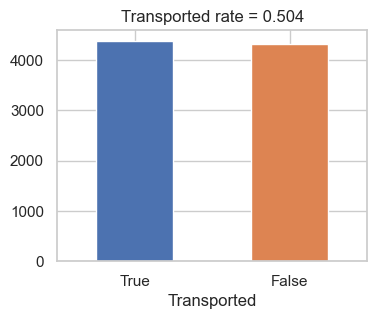

In [3]:
ax = train["Transported"].value_counts().plot.bar(figsize=(4,3), color=["C0","C1"])
ax.set_title(f"Transported rate = {train.Transported.mean():.3f}"); plt.xticks(rotation=0); plt.show()

## 2. Missing values
Every feature column has about 2% missing values, scattered at random, but that adds up to **24% of rows with at least one missing value**.
Simply dropping those rows would waste a lot of data, so we impute using the dataset's structure (see section 7).

In [4]:
miss = pd.DataFrame({"train %": train.isna().mean()*100, "test %": test.isna().mean()*100}).round(2)
print(f"Rows with any NA: {train.isna().any(axis=1).mean():.1%}")
miss

Rows with any NA: 24.0%


,train %,test %
Age,2.06,2.13
Cabin,2.29,2.34
CryoSleep,2.50,2.17
Destination,2.09,2.15
FoodCourt,2.11,2.48
HomePlanet,2.31,2.03
Name,2.30,2.20
PassengerId,0.00,0.00
RoomService,2.08,1.92
ShoppingMall,2.39,2.29


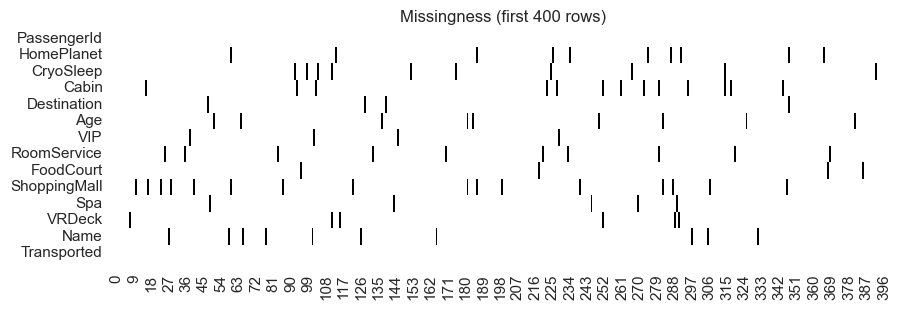

In [5]:
fig, ax = plt.subplots(figsize=(10,3))
sns.heatmap(train.isna().iloc[:400].T, cbar=False, ax=ax, cmap="Greys"); ax.set_title("Missingness (first 400 rows)")
plt.show()

## 3. Parse composite columns
`PassengerId` = `gggg_pp` (group / person). `Cabin` = `deck/num/side`.

In [6]:
df = train.copy()
df["Group"] = df.PassengerId.str[:4].astype(int)
df["GroupSize"] = df.groupby("Group").Group.transform("size")
cab = df.Cabin.str.split("/", expand=True)
df["Deck"], df["CabinNum"], df["Side"] = cab[0], pd.to_numeric(cab[1]), cab[2]
df["Surname"] = df.Name.str.split().str[-1]
df["TotalSpend"] = df[SPEND].sum(axis=1)
df[["PassengerId","Group","GroupSize","Deck","CabinNum","Side","Surname","TotalSpend"]].head()

,PassengerId,Group,GroupSize,Deck,CabinNum,Side,Surname,TotalSpend
0,0001_01,1,1,B,0.0,P,Ofracculy,0.0
1,0002_01,2,1,F,0.0,S,Vines,736.0
2,0003_01,3,2,A,0.0,S,Susent,10383.0
3,0003_02,3,2,A,0.0,S,Susent,5176.0
4,0004_01,4,1,F,1.0,S,Santantines,1091.0


## 4. Categorical features vs target

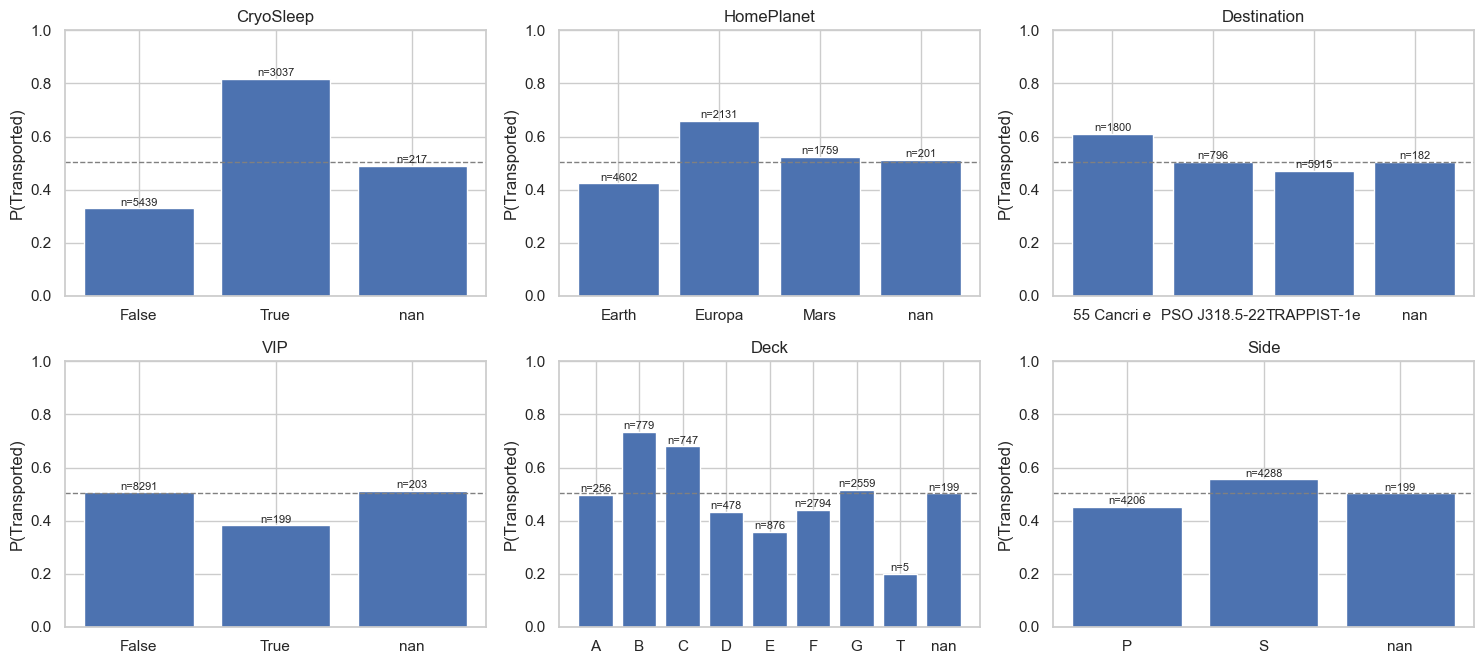

In [7]:
def rate_plot(cols, ncols=3):
    nrows = int(np.ceil(len(cols)/ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 3.4*nrows))
    for ax, c in zip(np.ravel(axes), cols):
        g = df.groupby(c, dropna=False).Transported.agg(["mean","size"])
        ax.bar(g.index.astype(str), g["mean"], color="C0")
        ax.axhline(df.Transported.mean(), ls="--", c="grey", lw=1)
        for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
            ax.text(i, m+0.01, f"n={n}", ha="center", fontsize=8)
        ax.set_title(c); ax.set_ylim(0, 1); ax.set_ylabel("P(Transported)")
    for ax in np.ravel(axes)[len(cols):]: ax.axis("off")
    plt.tight_layout(); plt.show()

rate_plot(["CryoSleep", "HomePlanet", "Destination", "VIP", "Deck", "Side"])

**Takeaways**
- **CryoSleep is the strongest single feature**: 82% of sleepers were transported, compared with 33% of passengers who were awake.
- Europa (66%) is above the 50% baseline and Earth (42%) is below it. 55 Cancri e is the destination with the highest rate.
- Decks B and C are high and deck E is low. Starboard (S) is higher than port (P): 55% vs 45%.
- VIP is rare (2%) and weak. Deck T has only 5 passengers.

## 5. Age

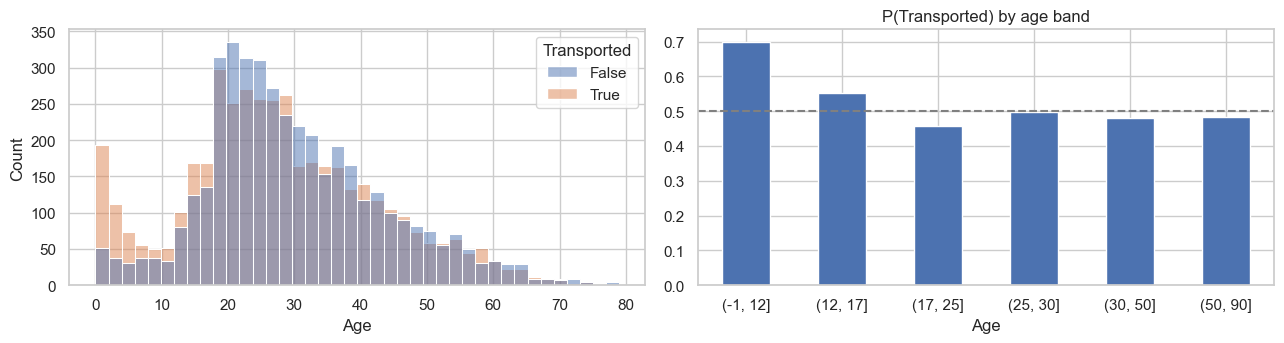

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13,3.6))
sns.histplot(df, x="Age", hue="Transported", binwidth=2, multiple="layer", ax=axes[0])
bins = pd.cut(df.Age, [-1,12,17,25,30,50,90])
df.groupby(bins).Transported.mean().plot.bar(ax=axes[1], color="C0")
axes[1].axhline(0.5, ls="--", c="grey"); axes[1].set_title("P(Transported) by age band"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

Children aged 12 and under were transported far more often (70%), and young adults aged 18–25 less often. The effect is not linear, so a binned age feature helps tree models.

## 6. Spending

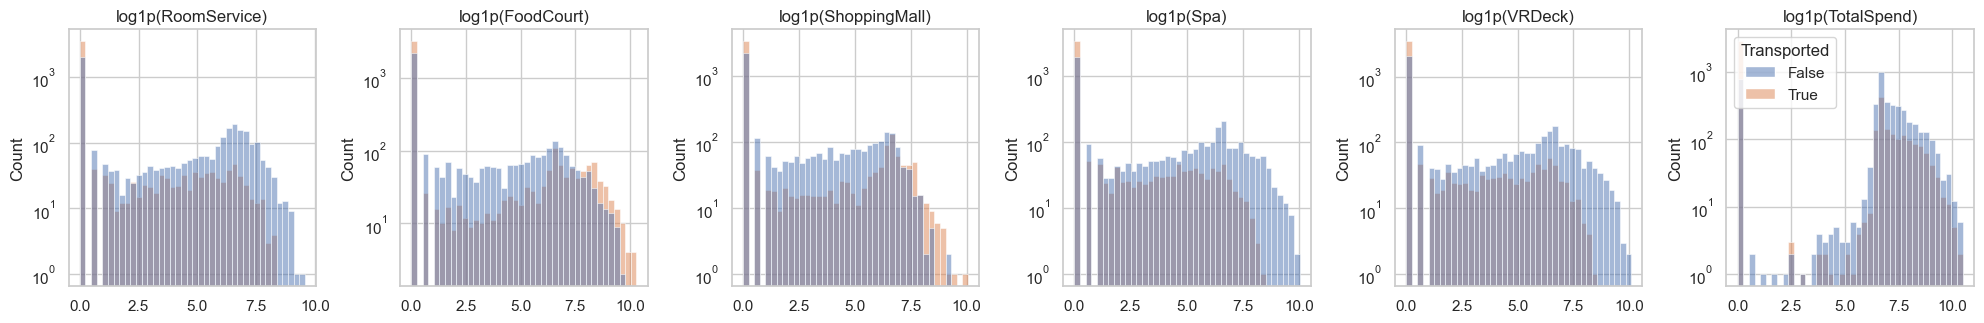

In [9]:
fig, axes = plt.subplots(1, 6, figsize=(20,3.4))
for ax, c in zip(axes, SPEND + ["TotalSpend"]):
    sns.histplot(df, x=np.log1p(df[c]), hue="Transported", bins=40, ax=ax, legend=(c=="TotalSpend"))
    ax.set_title(f"log1p({c})"); ax.set_xlabel(""); ax.set_yscale("log")
plt.tight_layout(); plt.show()

In [10]:
pd.DataFrame({c: df.groupby(df[c] > 0).Transported.mean() for c in SPEND + ["TotalSpend"]}) \
  .rename(index={False: "spent 0", True: "spent > 0"}).round(3)

,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,TotalSpend
spent 0,0.628,0.589,0.597,0.634,0.624,0.786
spent > 0,0.260,0.345,0.317,0.277,0.275,0.299


**Takeaways**
- Spending is heavily right-skewed, with most values at 0. A `log1p` transform is used.
- Passengers who **spent nothing** were transported 79% of the time, compared with 30% of those who spent something.
- **Luxury** spending (RoomService, Spa, VRDeck) separates the classes more strongly than **basic** spending (FoodCourt, ShoppingMall). Hence the `LuxurySpend` and `BasicSpend` features.

## 7. Structural rules used for imputation

In [11]:
checks = {
    "CryoSleep=True AND spent > 0": ((df.CryoSleep == True) & (df.TotalSpend > 0)).sum(),
    "Age < 13 AND spent > 0": ((df.Age < 13) & (df.TotalSpend > 0)).sum(),
    "Groups with >1 HomePlanet": (df.groupby("Group").HomePlanet.nunique() > 1).sum(),
    "Groups with >1 Side": (df.groupby("Group").Side.nunique() > 1).sum(),
    "Groups with >1 Deck": (df.groupby("Group").Deck.nunique() > 1).sum(),
    "Surnames with >1 HomePlanet": (df.groupby("Surname").HomePlanet.nunique() > 1).sum(),
    "VIPs from Earth": ((df.VIP == True) & (df.HomePlanet == "Earth")).sum(),
}
pd.Series(checks, name="count").to_frame()

,count
CryoSleep=True AND spent > 0,0
Age < 13 AND spent > 0,0
Groups with >1 HomePlanet,0
Groups with >1 Side,0
Groups with >1 Deck,421
Surnames with >1 HomePlanet,0
VIPs from Earth,0


In [12]:
pd.crosstab(df.Deck, df.HomePlanet)

HomePlanet,Earth,Europa,Mars
Deck,,,
A,0,252,0
B,0,766,0
C,0,734,0
D,0,186,282
E,395,128,330
F,1614,0,1110
G,2498,0,0
T,0,4,0


Hard rules found in the data:
- **Sleepers never spend** and **children under 13 never spend**. A missing spend value can be set to 0 for those passengers, and anyone with spending above 0 was awake.
- **Group members always share HomePlanet and Side.** They usually share a deck, but 421 groups span more than one.
- Surnames almost always map to one HomePlanet.
- **Decks A, B, C and T are Europa only. Deck G is Earth only.** Deck F is Earth or Mars.

## 8. Groups and cabin location

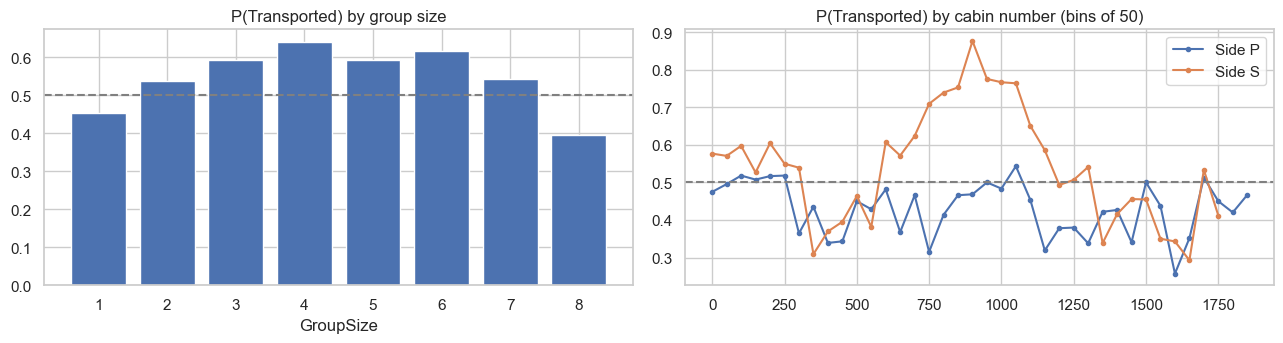

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13,3.6))
g = df.groupby("GroupSize").Transported.agg(["mean","size"])
axes[0].bar(g.index, g["mean"]); axes[0].axhline(0.5, ls="--", c="grey"); axes[0].set_title("P(Transported) by group size")
axes[0].set_xlabel("GroupSize")
for side, d in df.dropna(subset=["CabinNum"]).groupby("Side"):
    r = d.groupby(d.CabinNum // 50 * 50).Transported.mean()
    axes[1].plot(r.index, r.values, marker=".", label=f"Side {side}")
axes[1].axhline(0.5, ls="--", c="grey"); axes[1].legend(); axes[1].set_title("P(Transported) by cabin number (bins of 50)")
plt.tight_layout(); plt.show()

- **Solo travellers** were transported less often (45%). Groups of 3 to 6 were transported about 60% of the time.
- The transport rate drifts **in bands along the cabin number**, so `CabinRegion = CabinNum // 300` captures that.
- Cabin numbers rise steadily with group id within each deck, so a missing `CabinNum` is filled by linear interpolation.

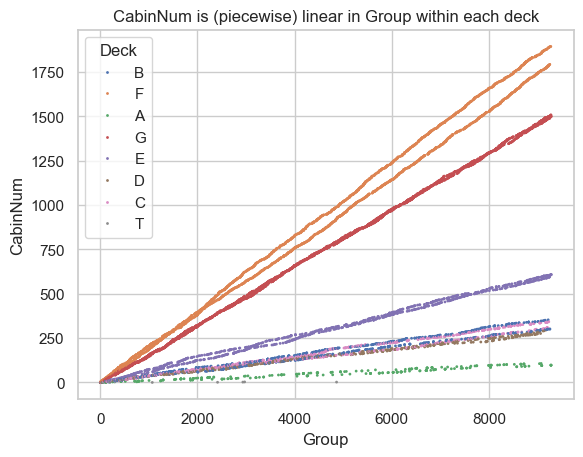

In [14]:
sns.scatterplot(data=df.dropna(subset=["CabinNum"]), x="Group", y="CabinNum", hue="Deck", s=4, linewidth=0)
plt.title("CabinNum is (piecewise) linear in Group within each deck"); plt.show()

## 9. Interactions

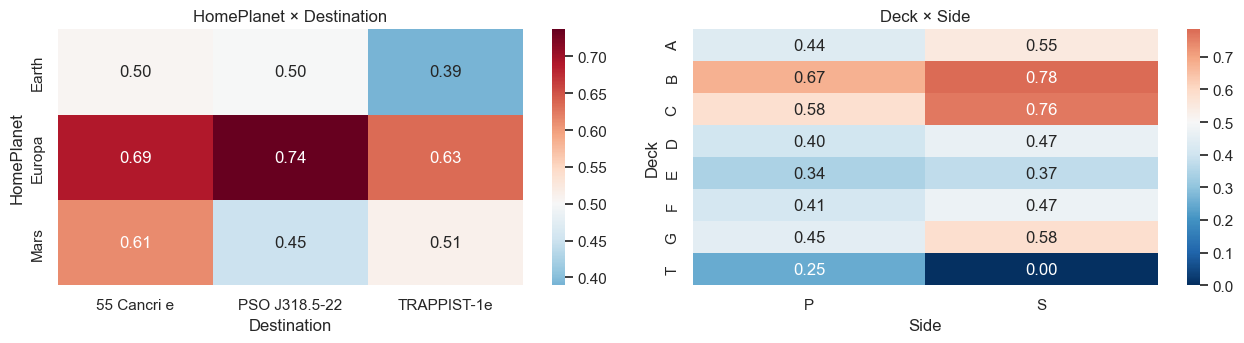

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13,3.6))
sns.heatmap(pd.crosstab(df.HomePlanet, df.Destination, values=df.Transported, aggfunc="mean"),
            annot=True, fmt=".2f", cmap="RdBu_r", center=0.5, ax=axes[0]); axes[0].set_title("HomePlanet × Destination")
sns.heatmap(pd.crosstab(df.Deck, df.Side, values=df.Transported, aggfunc="mean"),
            annot=True, fmt=".2f", cmap="RdBu_r", center=0.5, ax=axes[1]); axes[1].set_title("Deck × Side")
plt.tight_layout(); plt.show()

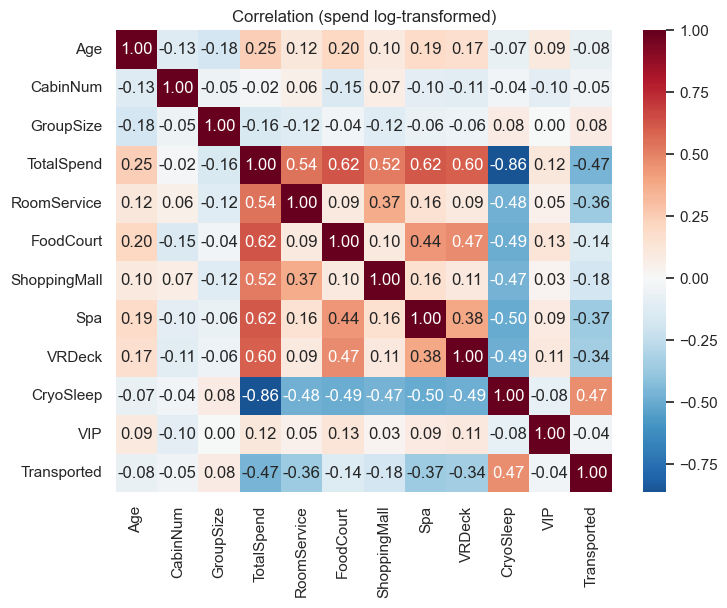

In [16]:
num = df[["Age","CabinNum","GroupSize","TotalSpend"] + SPEND].copy()
num[SPEND + ["TotalSpend"]] = np.log1p(num[SPEND + ["TotalSpend"]])
num["CryoSleep"] = df.CryoSleep.astype(float); num["VIP"] = df.VIP.astype(float)
num["Transported"] = df.Transported.astype(float)
plt.figure(figsize=(8,6)); sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation (spend log-transformed)"); plt.show()

## 10. Summary → modelling decisions

| Finding | Used in `solution.py` |
|---|---|
| CryoSleep and zero spending are the strongest signals | `CryoSleep`, `NoSpend`, log spend features |
| Luxury and basic spending behave differently | `LuxurySpend`, `BasicSpend` |
| Age effect is non-linear (children are high) | `AgeBin` |
| Deck, Side and cabin-number bands matter | `Deck`, `Side`, `DeckSide`, `CabinRegion` |
| Group size matters | `GroupSize`, `Solo`, `FamilySize` |
| Hard rules (sleepers and children don't spend; groups share planet and side; deck→planet) | Rule-based imputation instead of a blanket median |
| Train and test distributions match (next cell) | Plain stratified K-fold CV is a reliable estimate |

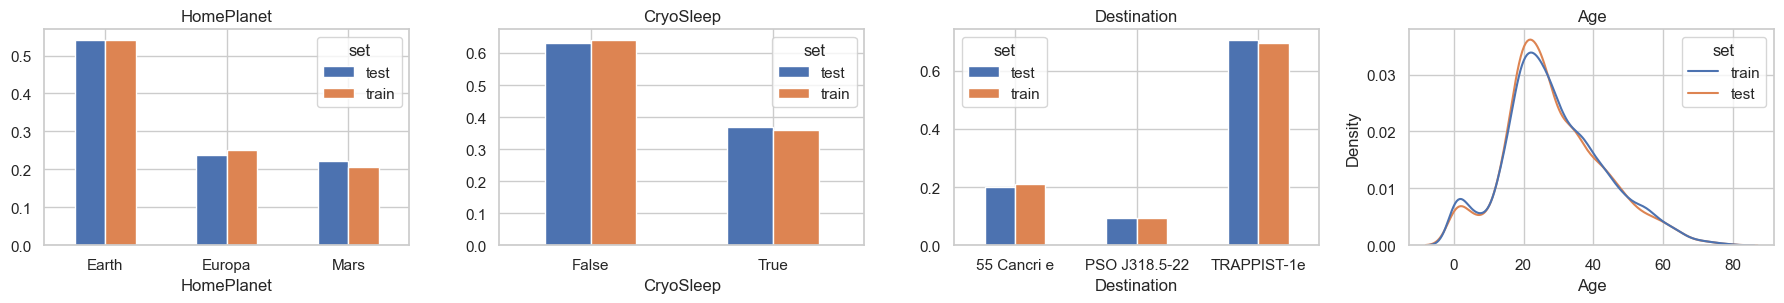

In [17]:
both = pd.concat([train.assign(set="train"), test.assign(set="test")], ignore_index=True)
fig, axes = plt.subplots(1, 4, figsize=(18,3.2))
for ax, c in zip(axes, ["HomePlanet","CryoSleep","Destination"]):
    pd.crosstab(both[c], both.set, normalize="columns").plot.bar(ax=ax, rot=0); ax.set_title(c)
sns.kdeplot(data=both, x="Age", hue="set", common_norm=False, ax=axes[3]); axes[3].set_title("Age")
plt.tight_layout(); plt.show()